<a href="https://colab.research.google.com/github/Koushikdubey/Capstone-Projrct-Python-/blob/main/Capstone_Project_(Global_Music_Streaming_Listener_Preferences).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/Global_Music_Streaming_Listener_Preferences.csv")

df

,User_ID,Age,Country,Streaming Platform,Top Genre,Minutes Streamed Per Day,Number of Songs Liked,Most Played Artist,Subscription Type,Listening Time (Morning/Afternoon/Night),Discover Weekly Engagement (%),Repeat Song Rate (%)
0,U1000,34,Japan,Tidal,Reggae,295,138,Adele,Free,Afternoon,47.42,16.74
1,U1001,24,Germany,Deezer,Country,86,388,Ed Sheeran,Premium,Night,12.06,69.25
2,U1002,49,Germany,Deezer,Pop,363,368,Post Malone,Premium,Afternoon,47.19,67.38
3,U1003,55,Australia,YouTube,Reggae,348,349,Dua Lipa,Premium,Morning,31.27,76.51
4,U1004,13,Germany,Amazon Music,Reggae,30,328,Adele,Free,Night,30.68,43.41
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,U5995,60,UK,Deezer,Country,348,81,Post Malone,Premium,Morning,49.23,22.36
4996,U5996,38,Australia,Deezer,Hip-Hop,225,218,BTS,Premium,Night,17.08,58.23
4997,U5997,27,Brazil,Amazon Music,Metal,568,277,Taylor Swift,Premium,Night,69.39,51.71
4998,U5998,58,Canada,Amazon Music,EDM,523,492,Bad Bunny,Premium,Night,43.44,24.53


In [2]:
df.describe()

,Age,Minutes Streamed Per Day,Number of Songs Liked,Discover Weekly Engagement (%),Repeat Song Rate (%)
count,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,36.664000,309.237200,253.51720,50.296464,42.391060
std,13.763844,172.029822,146.36928,23.171936,21.444121
min,13.000000,10.000000,1.00000,10.020000,5.000000
25%,25.000000,161.000000,126.00000,30.147500,24.195000
50%,37.000000,316.000000,254.00000,50.420000,41.960000
75%,49.000000,457.250000,382.00000,70.337500,60.740000
max,60.000000,600.000000,500.00000,89.990000,79.990000


# **EDA**

In [3]:
# Null Value Check

df.isnull().sum()

,0
User_ID,0
Age,0
Country,0
Streaming Platform,0
Top Genre,0
Minutes Streamed Per Day,0
Number of Songs Liked,0
Most Played Artist,0
Subscription Type,0
Listening Time (Morning/Afternoon/Night),0


In [4]:
# Duplicate Check

df.duplicated().sum()

np.int64(0)

In [5]:
# Unique Value Check

df["Country"].unique()

array(['Japan', 'Germany', 'Australia', 'South Korea', 'UK', 'Brazil',
       'Canada', 'India', 'USA', 'France'], dtype=object)

In [6]:
# Coloumn Check In Dataset

df.columns

Index(['User_ID', 'Age', 'Country', 'Streaming Platform', 'Top Genre',
       'Minutes Streamed Per Day', 'Number of Songs Liked',
       'Most Played Artist', 'Subscription Type',
       'Listening Time (Morning/Afternoon/Night)',
       'Discover Weekly Engagement (%)', 'Repeat Song Rate (%)'],
      dtype='object')

In [7]:
# Category find/check of the feature

categorical_features = [feature for feature in df.columns if df[feature].dtypes == 'O']
categorical_features

['User_ID',
 'Country',
 'Streaming Platform',
 'Top Genre',
 'Most Played Artist',
 'Subscription Type',
 'Listening Time (Morning/Afternoon/Night)']

In [8]:
# Unique Value check for all the feature/column

for column in categorical_features:
  unique_values = df[column].unique()
  print(f"{column}: {unique_values}")

User_ID: ['U1000' 'U1001' 'U1002' ... 'U5997' 'U5998' 'U5999']
Country: ['Japan' 'Germany' 'Australia' 'South Korea' 'UK' 'Brazil' 'Canada'
 'India' 'USA' 'France']
Streaming Platform: ['Tidal' 'Deezer' 'YouTube' 'Amazon Music' 'Spotify' 'Apple Music']
Top Genre: ['Reggae' 'Country' 'Pop' 'EDM' 'Classical' 'Metal' 'Rock' 'Hip-Hop' 'R&B'
 'Jazz']
Most Played Artist: ['Adele' 'Ed Sheeran' 'Post Malone' 'Dua Lipa' 'The Weeknd'
 'Billie Eilish' 'BTS' 'Taylor Swift' 'Drake' 'Bad Bunny']
Subscription Type: ['Free' 'Premium']
Listening Time (Morning/Afternoon/Night): ['Afternoon' 'Night' 'Morning']


In [9]:
# Drop Unnecessary Feature(column)

if "User_ID" in df.columns:
    df = df.drop("User_ID" , axis=1)
df

,Age,Country,Streaming Platform,Top Genre,Minutes Streamed Per Day,Number of Songs Liked,Most Played Artist,Subscription Type,Listening Time (Morning/Afternoon/Night),Discover Weekly Engagement (%),Repeat Song Rate (%)
0,34,Japan,Tidal,Reggae,295,138,Adele,Free,Afternoon,47.42,16.74
1,24,Germany,Deezer,Country,86,388,Ed Sheeran,Premium,Night,12.06,69.25
2,49,Germany,Deezer,Pop,363,368,Post Malone,Premium,Afternoon,47.19,67.38
3,55,Australia,YouTube,Reggae,348,349,Dua Lipa,Premium,Morning,31.27,76.51
4,13,Germany,Amazon Music,Reggae,30,328,Adele,Free,Night,30.68,43.41
...,...,...,...,...,...,...,...,...,...,...,...
4995,60,UK,Deezer,Country,348,81,Post Malone,Premium,Morning,49.23,22.36
4996,38,Australia,Deezer,Hip-Hop,225,218,BTS,Premium,Night,17.08,58.23
4997,27,Brazil,Amazon Music,Metal,568,277,Taylor Swift,Premium,Night,69.39,51.71
4998,58,Canada,Amazon Music,EDM,523,492,Bad Bunny,Premium,Night,43.44,24.53


## **Univeriate Analysis (Single Feature Analysis)**

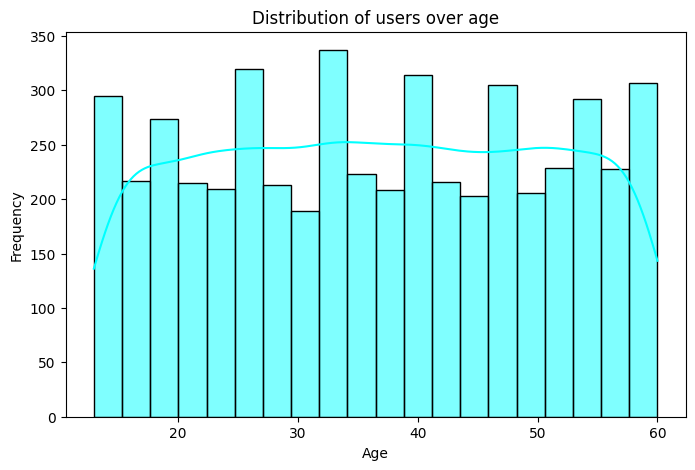

In [10]:
# Distribution of users over age

plt.figure(figsize=(8,5))
sns.histplot(df["Age"], bins=20, kde=True, color="cyan")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Distribution of users over age")
plt.show()

/tmp/ipykernel_2638/280305805.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x= df["Streaming Platform"], order=df["Streaming Platform"].value_counts().index, palette="Set1")


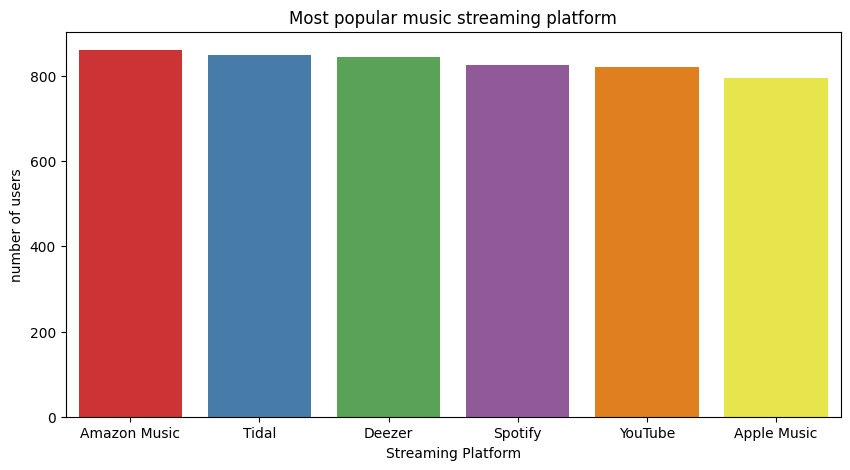

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Popular Streaming Platform

plt.figure(figsize=(10,5))
sns.countplot(x= df["Streaming Platform"], order=df["Streaming Platform"].value_counts().index, palette="Set1")
plt.xlabel("Streaming Platform")
plt.ylabel("number of users")
plt.title("Most popular music streaming platform")
plt.show()

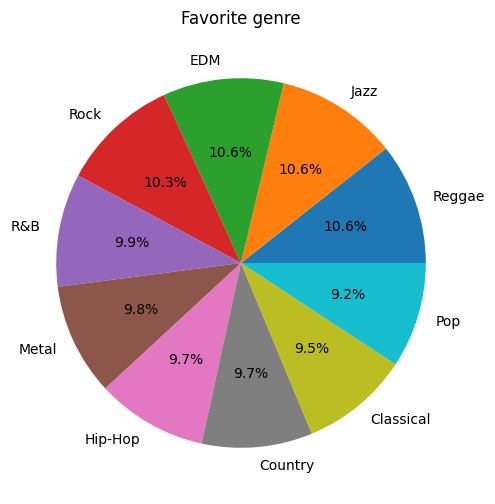

In [12]:
# Calculate Top Genre

top_genre = df["Top Genre"].value_counts()
plt.figure(figsize=(8,6))
plt.pie(top_genre, labels = top_genre.index, autopct= '%1.1f%%')
plt.title("Favorite genre")
plt.show()

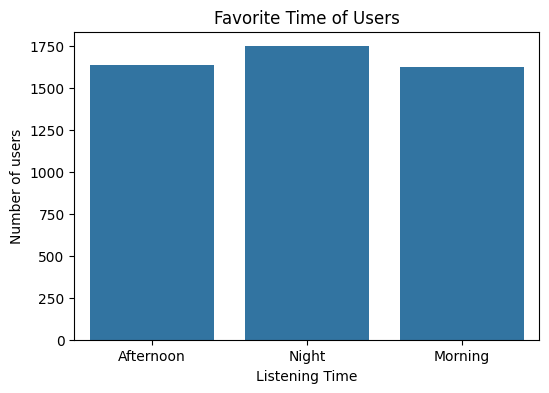

In [13]:
# Favorable Time of Users to listen to Songs

plt.figure(figsize=(6,4))
sns.countplot(x=df["Listening Time (Morning/Afternoon/Night)"])
plt.title("Favorite Time of Users")
plt.xlabel("Listening Time")
plt.ylabel("Number of users")
plt.show()


## **Bivariate and Multivariate Analysis**

In [14]:
df.head(2)

,Age,Country,Streaming Platform,Top Genre,Minutes Streamed Per Day,Number of Songs Liked,Most Played Artist,Subscription Type,Listening Time (Morning/Afternoon/Night),Discover Weekly Engagement (%),Repeat Song Rate (%)
0,34,Japan,Tidal,Reggae,295,138,Adele,Free,Afternoon,47.42,16.74
1,24,Germany,Deezer,Country,86,388,Ed Sheeran,Premium,Night,12.06,69.25


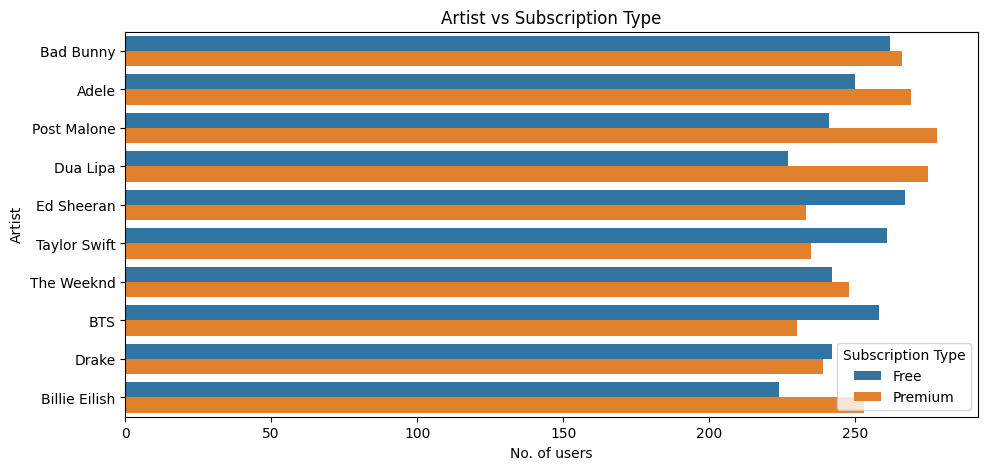

In [15]:
plt.figure( figsize=(11,5))
sns.countplot(data=df, y="Most Played Artist" , hue="Subscription Type", order=df["Most Played Artist"].value_counts().index[:10])
plt.title("Artist vs Subscription Type")
plt.xlabel("No. of users")
plt.ylabel("Artist")
plt.show()

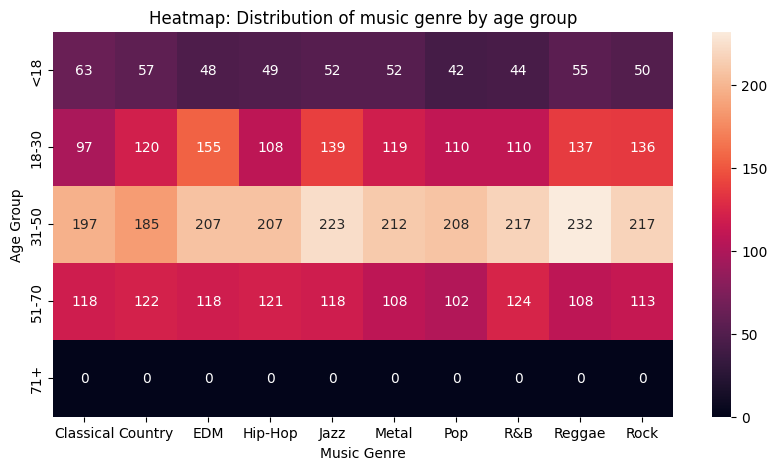

In [16]:
# Distribution of Music Genre by Age Group

bins = [0, 18, 30,50,70,100]
labels = ['<18', '18-30', '31-50', '51-70', '71+']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)

genre_age_counts = df.groupby(["Age Group", "Top Genre"], observed=False).size().unstack().fillna(0)

plt.figure(figsize=(10,5))

sns.heatmap(genre_age_counts, annot=True, fmt='d')
plt.title("Heatmap: Distribution of music genre by age group")
plt.xlabel("Music Genre")
plt.ylabel("Age Group")
plt.show()

In [20]:
subscriptiontype = df.groupby("Subscription Type")["Minutes Streamed Per Day"].count()
subscriptiontype

,Minutes Streamed Per Day
Subscription Type,
Free,2474
Premium,2526
